In [8]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# load the dataset
data = pd.read_csv('assignTTSWING.csv')

In [25]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

# Drop label and obviously irrelevant columns
X = data.drop(columns=[
    'id', 'date', 'testmode', 'teststage', 'fileindex', 'count',
    'gender', 'newv1', 'newv2', 'newv3', 'newv4', 'handedness', 'holdRacketHanded'
], errors='ignore')

# Keep only numeric columns (this avoids errors like 'high')
X = X.select_dtypes(include=[np.number])

# Double-check what features you're left with
print("Final selected numeric features:", X.columns.tolist())

# Extract label
y = data['gender'].map({'female': 0, 'male': 1}) if data['gender'].dtype == 'object' else data['gender']

# Standardize
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Display the result
print(X_scaled_df.head())


Final selected numeric features: ['ax_mean', 'ay_mean', 'az_mean', 'gx_mean', 'gy_mean', 'gz_mean', 'ax_var', 'ay_var', 'az_var', 'gx_var', 'gy_var', 'gz_var', 'ax_rms', 'ay_rms', 'az_rms', 'gx_rms', 'gy_rms', 'gz_rms', 'a_max', 'a_mean', 'a_min', 'g_max', 'g_mean', 'g_min', 'a_fft', 'g_fft', 'a_psdx', 'g_psdx', 'a_kurt', 'g_kurt', 'a_skewn', 'g_skewn', 'a_entropy', 'g_entropy']
    ax_mean   ay_mean   az_mean   gx_mean   gy_mean   gz_mean    ax_var  \
0  0.651414  0.357713  0.345676  0.520029  0.483874  0.626968  0.001481   
1  0.618327  0.339254  0.351924  0.493775  0.538952  0.679812  0.159211   
2  0.497682  0.216484  0.464206  0.521647  0.504676  0.643844  0.561289   
3  0.470375  0.189607  0.512427  0.557001  0.507756  0.616481  0.618089   
4  0.452888  0.185791  0.517751  0.563109  0.491220  0.629955  0.614809   

     ay_var    az_var    gx_var  ...     a_fft     g_fft    a_psdx    g_psdx  \
0  0.002300  0.003408  0.009712  ...  0.261261  0.188815  0.386100  0.391667   
1  0.12

In [26]:
#Import feature selection method
from sklearn.feature_selection import SelectKBest, f_classif

# Select top 10 features most correlated with gender
selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X_scaled_df, y)

# Get selected feature names and their scores
mask = selector.get_support()
selected_features = X_scaled_df.columns[mask]
feature_scores = selector.scores_[mask]

# Combine and display nicely
import pandas as pd
selected_df = pd.DataFrame({
    'Feature': selected_features,
    'F-Score': feature_scores
}).sort_values(by='F-Score', ascending=False)

print(selected_df)


   Feature      F-Score
7   gx_rms  2295.199082
1  ay_mean  1856.237311
5   gx_var  1505.899286
4  gy_mean  1233.126427
0  ax_mean   885.047431
2  az_mean   659.286165
8    a_max   527.420943
6   ax_rms   495.567605
9  g_skewn   443.706876
3  gx_mean   245.444669


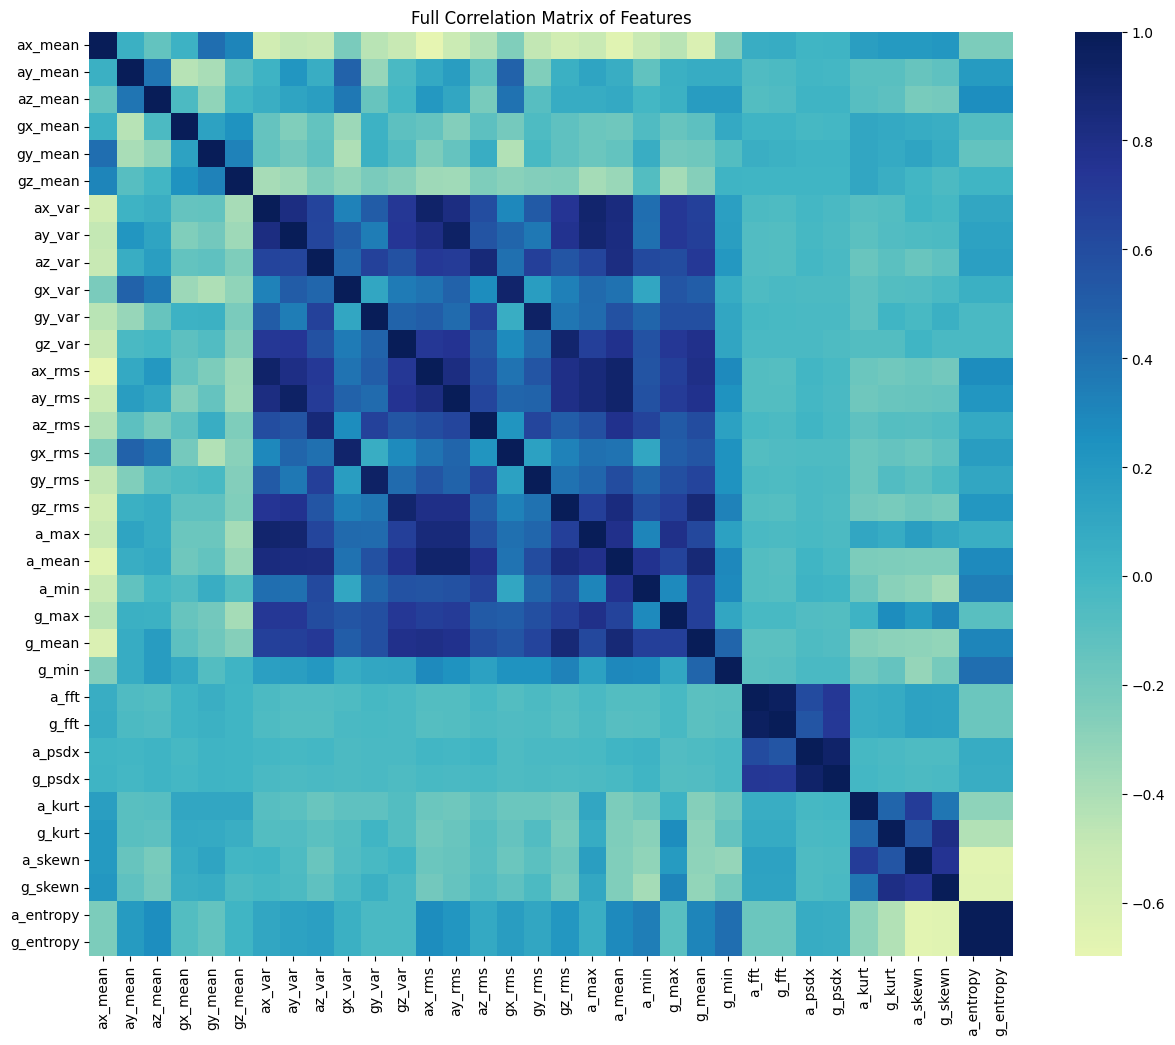

In [27]:
# check the first few rows of the dataset
plt.figure(figsize=(16, 12))
sns.heatmap(X_scaled_df.corr(), cmap='YlGnBu', center=0, square=True)
plt.title("Full Correlation Matrix of Features")
plt.show()

In [ ]:
corr_matrix = X_scaled_df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Drop features with correlation > 0.90, choosing 0.9 because do not want to aggressively drop features or else we might lose important information
to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
print("Highly correlated features to drop:", to_drop)

X_deduped = X_scaled_df.drop(columns=to_drop)   

Highly correlated features to drop: ['ax_rms', 'ay_rms', 'gx_rms', 'gy_rms', 'gz_rms', 'a_max', 'a_mean', 'g_fft', 'g_psdx', 'g_entropy']


In [29]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_deduped, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Initialize and fit the logistic regression model
logistic_regression_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression_model.fit(X_train, y_train)
y_pred_logistic_regression = logistic_regression_model.predict(X_test)

print("Logistic Regression Performance:\n")
print(classification_report(y_test, y_pred_logistic_regression))



Logistic Regression Performance:

              precision    recall  f1-score   support

           0       0.55      0.28      0.37      7711
           1       0.64      0.85      0.73     11760

    accuracy                           0.63     19471
   macro avg       0.60      0.57      0.55     19471
weighted avg       0.61      0.63      0.59     19471



In [30]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and fit the Random Forest model
random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(X_train, y_train)  
y_pred_random_forest = random_forest_model.predict(X_test)

print("Random Forest Performance:\n")
print(classification_report(y_test, y_pred_random_forest))


Random Forest Performance:

              precision    recall  f1-score   support

           0       0.92      0.83      0.87      7711
           1       0.90      0.95      0.92     11760

    accuracy                           0.90     19471
   macro avg       0.91      0.89      0.90     19471
weighted avg       0.90      0.90      0.90     19471



In [32]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Accuracy
from tensorflow.keras.losses import BinaryCrossentropy
from sklearn.metrics import classification_report

model = Sequential([
    Dense(64, input_dim=X_train.shape[1], activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')  # Output layer for binary classification
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=BinaryCrossentropy(),
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

# Predict (returns probabilities, so threshold at 0.5)
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype(int)

# Flatten y_test if needed
y_test_flat = y_test.values if hasattr(y_test, 'values') else y_test

# Evaluate
print("DNN Performance:\n")
print(classification_report(y_test_flat, y_pred))


Epoch 1/20


c:\Users\shiva\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1948/1948 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.6051 - loss: 0.6571 - val_accuracy: 0.6440 - val_loss: 0.6206
Epoch 2/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.6608 - loss: 0.6065 - val_accuracy: 0.6910 - val_loss: 0.5703
Epoch 3/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7003 - loss: 0.5679 - val_accuracy: 0.7225 - val_loss: 0.5456
Epoch 4/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7130 - loss: 0.5471 - val_accuracy: 0.7188 - val_loss: 0.5483
Epoch 5/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7242 - loss: 0.5337 - val_accuracy: 0.7376 - val_loss: 0.5165
Epoch 6/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7324 - loss: 0.5201 - val_accuracy: 0.7273 - val_loss: 0.5180
Epoch 7/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7386 - loss: 0.5094 - val_accuracy: 0.7439 - val_loss: 0.5018
Epoch 8/20
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7460 - loss: 0.4997 - val_accurac

In [ ]:
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
